# REINVENT4 tutorial using Maize



In [1]:
import math
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
import mols2grid

from IPython.display import display

sns.set(style="darkgrid")
pd.set_option("display.precision", 3)

## Utility functions

Useful functions to display molecules in a grid and to show a 3D conformation of a molecule.

In [2]:
def show_mol_grid(df, cols=None, smiles_col='SMILES', mol_col=None, transform={}):

    if cols:
        subset = ['img'].append(cols)
    else:
        subset = ['img']

    if mol_col:
        mol_view = mols2grid.display(df, mol_col=mol_col,
                                     subset=subset, n_rows=5, n_cols=6, selection=False,
                                     transform=transform, useSVG=True, size=(150, 150))
    else:
        mol_view = mols2grid.display(df, smiles_col=smiles_col,
                                     subset=subset, n_rows=5, n_cols=6, selection=False,
                                     transform=transform, useSVG=True, size=(150, 150))

    display(mol_view)

import py3Dmol

def show_mol_3d(mol):
    view = py3Dmol.view(width=500, height=500)
    view.removeAllModels()
    
    IPythonConsole.addMolToView(mol, view, confId=0)
    
    view.zoomTo()
    view.show()
    
import nglview as ngl  # requires nodejs from conda
import ipywidgets as widgets

class ShowLigand:
    def __init__(self, view, mols):
        self.view = view
        self.mols = mols
        self.id = None
        
        self.ligand_dropdown = widgets.Dropdown(
            options=[(self.mols[i].GetProp("SMILES"), i) for i, m in enumerate(self.mols)],
            description="SMILES:",
            style={'description_width': 'initial'},
        )

        widgets.interactive_output(self._show_ligand, {"index": self.ligand_dropdown})

    def _show_ligand(self, index):
        if self.id is not None:
            try:
                self.view.remove_component(self.id)
            except Exception:
                pass
    
        self.id = self.view.add_component(self.mols[index])
        self.view[1].add_ball_and_stick
        
    def show(self):
        display(widgets.VBox([self.view, self.ligand_dropdown]))        

/home/sofki/miniconda3/envs/reinvent4/lib/python3.10/site-packages/nglview/__init__.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Exploring the data

The data has been post-process after the REINVENT to filter down the original set of 60,000 molecules.  The filter removes invalid molecules, duplicates and discards all molecules with a score lower than a threshold in any of its individual scores.  We also assume that a predicted free energy (the docking score really) of -14.0 kcal/should and smaller provides sufficiently reasonable docked poses for further processing.  The 3D conformations/poses of the final subset are stored in a separate SD file.

In [3]:
df = pd.read_csv("filtered_matched_unique.csv")

In [4]:
df


,Agent,Prior,Target,Score,SMILES,SMILES_state,Input_Scaffold,R-groups,# rotatable bonds (<10),# rotatable bonds (<10) (raw),...,Minimal Alerts,Minimal Alerts (raw),Maize ID (AutoDockGPU),matchting_patterns (Minimal Alerts),step,canonical_smiles,norm_smiles,source_sdf,pose_index,sdf_smiles
0,5.939,5.268,4.656,0.103,CCc1ccc(C(C)C)cc1,1,CC(C)c1ccc([*])cc1,CC*,0.997,2.0,...,1.0,1.0,GUUDUUDWUWUTPD-UHFFFAOYNA-N,[],2,CCc1ccc(C(C)C)cc1,CCc1ccc(C(C)C)cc1,best_pose-1.sdf,8,CCc1ccc(C(C)C)cc1
1,2.830,3.075,5.628,0.091,Cc1ccc(C(C)C)cc1,1,c1c(C([*])C)ccc(C)c1,C*,0.998,1.0,...,1.0,1.0,HFPZCAJZSCWRBC-UHFFFAOYNA-N,[],2,Cc1ccc(C(C)C)cc1,Cc1ccc(C(C)C)cc1,best_pose-1.sdf,17,Cc1ccc(C(C)C)cc1
2,9.553,7.771,0.176,0.083,CCc1ccc(C(C)C)cc1C,1,CC(c1cc([*])c([*])cc1)[*],C*|CC*|C*,0.997,2.0,...,1.0,1.0,NRTHCBJHTZAIOJ-UHFFFAOYNA-N,[],2,CCc1ccc(C(C)C)cc1C,CCc1ccc(C(C)C)cc1C,best_pose-1.sdf,33,CCc1ccc(C(C)C)cc1C
3,5.395,5.319,2.595,0.082,CC(C)c1ccc(N)cc1,1,c1c(C([*])C)ccc([*])c1,*C|N*,0.998,1.0,...,1.0,1.0,LRTFPLFDLJYEKT-UHFFFAOYNA-N,[],2,CC(C)c1ccc(N)cc1,CC(C)c1ccc(N)cc1,best_pose-1.sdf,62,CC(C)c1ccc(N)cc1
4,8.556,8.560,0.149,0.091,CCCc1ccc(C(C)C)cc1,1,CC(c1ccc([*])cc1)C,C(*)CC,0.994,3.0,...,1.0,1.0,FRGDRCOOSXPXDK-UHFFFAOYNA-N,[],11,CCCc1ccc(C(C)C)cc1,CCCc1ccc(C(C)C)cc1,best_pose-10.sdf,71,CCCc1ccc(C(C)C)cc1
5,9.206,7.496,0.540,0.084,CCc1ccc(C(C)N)cc1,1,C([*])(c1ccc([*])cc1)C,N*|C(*)C,0.997,2.0,...,1.0,1.0,AMXXYSXDJUIPMZ-QMMMGPOBNA-N,[],12,CCc1ccc(C(C)N)cc1,CCc1ccc(C(C)N)cc1,best_pose-11.sdf,59,CCc1ccc(C(C)N)cc1
6,8.723,8.585,-0.440,0.085,CCC(CC)c1ccc(C)cc1,1,c1(C)ccc(C([*])[*])cc1,*CC|*CC,0.994,3.0,...,1.0,1.0,HFPPJNVUPMBSBN-UHFFFAOYNA-N,[],17,CCC(CC)c1ccc(C)cc1,CCC(CC)c1ccc(C)cc1,best_pose-16.sdf,57,CCC(CC)c1ccc(C)cc1
7,7.105,6.451,2.136,0.089,CC(C)c1ccc(N(C)C)cc1,1,CC(c1ccc([*])cc1)C,N(C)(*)C,0.997,2.0,...,1.0,1.0,MJRUTYCVCLZWSR-UHFFFAOYNA-N,[],3,CC(C)c1ccc(N(C)C)cc1,CC(C)c1ccc(N(C)C)cc1,best_pose-2.sdf,17,CC(C)c1ccc(N(C)C)cc1
8,5.130,4.892,2.351,0.075,Cc1ccc(C(C)N)cc1,1,c1cc(C([*])[*])ccc1C,*C|*N,0.998,1.0,...,1.0,1.0,UZDDXUMOXKDXNE-GQNLNGBQNA-O,[],3,Cc1ccc(C(C)N)cc1,Cc1ccc(C(C)N)cc1,best_pose-2.sdf,69,Cc1ccc(C(C)N)cc1
9,6.609,6.566,2.080,0.090,CC(N)c1ccc(N)cc1,1,c1c(C([*])C)ccc([*])c1,N*|N*,0.998,1.0,...,1.0,1.0,CDSPOZXUDJUBEZ-ZCFIWIBFNA-N,[],22,CC(N)c1ccc(N)cc1,CC(N)c1ccc(N)cc1,best_pose-21.sdf,38,CC(N)c1ccc(N)cc1


### Distribution of the AutoDock score

Keep in mind that the original data has been filtered so naturally there will be an upper bound of the score at the originally chosen cutoff.

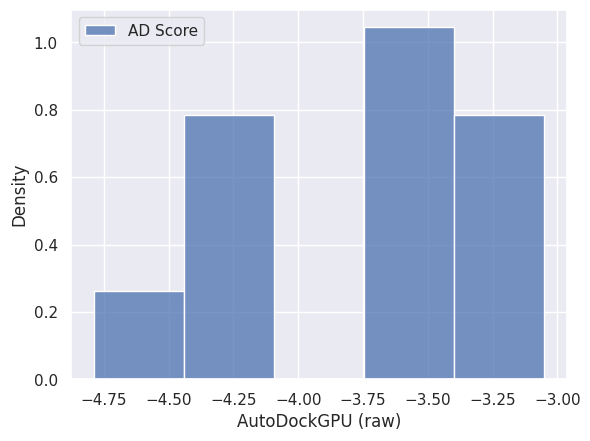

In [5]:
sns.histplot(data=df, x="AutoDockGPU (raw)", stat="density", label="AD Score")

plt.legend()
plt.show()

### Distribution of calculated logP

We look here only at the calculated logP which is often taken as a proxy for solubility and permeability.  The user is encouraged to explore the other scores as well.  See below for all the column names.

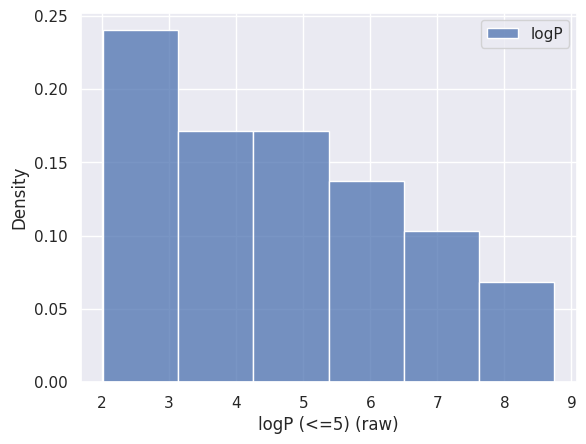

In [7]:
sns.histplot(data=df, x="logP (<=5) (raw)", stat="density", label="logP")

plt.legend()
plt.show()

###  All columns from the CSV file

In [8]:
df.columns

Index(['Agent', 'Prior', 'Target', 'Score', 'SMILES', 'SMILES_state',
       'Input_Scaffold', 'R-groups', '# rotatable bonds (<10)',
       '# rotatable bonds (<10) (raw)', '# stereo centers (<2)',
       '# stereo centers (<2) (raw)', 'Molecular weight (350-600)',
       'Molecular weight (350-600) (raw)', 'logP (<=5)', 'logP (<=5) (raw)',
       'TPSA (<=150)', 'TPSA (<=150) (raw)', '# aromatic rings (<5)',
       '# aromatic rings (<5) (raw)', '# Cl (<=1)', '# Cl (<=1) (raw)',
       '# F (<4)', '# F (<4) (raw)', '# HB-donors (<5)',
       '# HB-donors (<5) (raw)', '# HB-acceptors (<10)',
       '# HB-acceptors (<10) (raw)', 'AutoDockGPU', 'AutoDockGPU (raw)',
       'Minimal Alerts', 'Minimal Alerts (raw)', 'Maize ID (AutoDockGPU)',
       'matchting_patterns (Minimal Alerts)', 'step', 'canonical_smiles'],
      dtype='object')

### 2D display of filtered molecules

A 6-by-4 grid showing the 2D structure of each molecule together with all metadata from REINVENT, see the little "i" button in the top right of each box.

In [9]:
show_mol_grid(df, smiles_col='SMILES', cols=["AutoDockGPU (raw)"])

## Exploring the Gnina poses

The filtered poses from above have been subjected to local optimization with Gnina using the default CNN score for rescoring.  These poses are then further filtered by the `CNNscore` which basically is Gnina's confidence in how close it thinks the true pose is (within 2A).  This helps to further filter down the molecules.  There assumption here is made that Gnina provides better poses and scores for downstream tasks.

In [ ]:
suppl = Chem.SDMolSupplier("Reinvent/1DB5/best_pose_local.sdf")
mols = []

for mol in suppl:
    if mol:
        adgpu_score = mol.GetProp("m_score__min__energy")
        gnina_score = mol.GetProp("minimizedAffinity")
        gnina_cnn_score = mol.GetProp("CNNscore")
        gnina_cnn_affinity = mol.GetProp("CNNaffinity")
        gnina_rmsd = mol.GetProp("minimizedRMSD")
        mols.append((adgpu_score, gnina_score, gnina_cnn_score, gnina_cnn_affinity, gnina_rmsd, mol))

best = pd.DataFrame(mols, columns=["AD GPU score", "Gnina score", "Gnina CNN score",
                                   "Gnina CNN affinity", "Gnina RMSD", "Mol"])

In [ ]:
best[["AD GPU score", "Gnina score", "Gnina CNN score", "Gnina CNN affinity", "Gnina RMSD"]].round(3)

In [ ]:
show_mol_grid(best, mol_col="Mol", cols=["all"])

### Exploring 3D poses

In [9]:
sel_mol = best.Mol.iloc[3]
sel_mol

NameError: name 'best' is not defined

In [ ]:
show_mol_3d(sel_mol)

#### Show a specific pose in the 3D complex with the receptor

This uses the interactive [NGL viewer](https://nglviewer.org/nglview/latest/) embedded here in a notebook cell. You can switch to full-screem when pressing the little error in the top right of the rendering.

In [ ]:
ngl_view = ngl.show_file("adgpu_prepare/1DB5_apo.pdb")
ngl_view.add_representation('cartoon', selection='protein')
ngl_view.add_representation('ball+stick', selection='CA')
#ngl_view.add_representation('surface', selection='protein')

sl = ShowLigand(ngl_view, best.Mol)
sl.show()